# Statistical Arbitrage in Crypto: Momentum and Reversal

The question I wanted to answer: are there momentum or reversal patterns in crypto prices that are still profitable once you pay realistic trading costs?

Outline:
1. Data: 4-hour prices and volumes for 10 large coins from Binance
2. Time horizon: which look-back windows show reversal and which show momentum
3. Trying to make the signals stronger: volume, residual returns, seasonality, market regimes
4. Trading costs (20 bps per trade) and how to cut turnover
5. Combining the best reversal and momentum strategies
6. Performance: return, volatility, Sharpe, max drawdown, alpha and beta

To keep myself honest, every decision is made using 2021-2023 only (training period). I only look at 2024-2025 (test period) at the very end.

## Running the notebook

Install the packages once (cell below), then Kernel → Restart & Run All. The first run downloads the data from Binance, which takes a minute or two, and saves it to `prices_4h.csv` and `volumes_4h.csv`. After that the notebook reads from those files.

In [1]:
# Run this once to install the packages (remove the # at the start of the line)
# !pip install python-binance pandas numpy matplotlib

## 1. Data

Binance publishes its historical price data for free through a public API, so no account or API key is needed. I download it with the `python-binance` package. `client.get_historical_klines(symbol, interval, start, end)` returns candlesticks ("klines"), one row per 4-hour bar:

| Column | Meaning |
|---|---|
| `open_time` | start of the bar, in milliseconds since 1970 (converted to a date below) |
| `open`, `high`, `low`, `close` | prices during the bar |
| `volume` | number of coins traded |
| `quote_volume` | dollar (USDT) value traded, which is what I use as volume |

Some choices I made:
* 10 of the largest coins quoted in USDT, all listed on Binance before 2021.
* 4-hour bars (6 per day). Short enough to catch reversal, and the dataset stays small.
* Data starts in Nov 2020 so the 30-day look-backs are already filled in by Jan 2021.

Note: Binance.com blocks some locations (the US, Ontario, and cloud servers like Google Colab). If you get a "restricted location" error, switch `tld='com'` to `tld='us'` to use Binance.US.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from binance.client import Client as bnb_client

client = bnb_client(tld='com')   # use tld='us' if Binance.com is blocked where you are

def get_binance_px(symbol, freq, start_ts, end_ts):
    data = client.get_historical_klines(symbol, freq, start_ts, end_ts)
    columns = ['open_time','open','high','low','close','volume','close_time','quote_volume',
               'num_trades','taker_base_volume','taker_quote_volume','ignore']
    data = pd.DataFrame(data, columns=columns)
    data['open_time'] = pd.to_datetime(data['open_time'], unit='ms')   # convert milliseconds to dates
    return data

In [3]:
univ = ['BTCUSDT','ETHUSDT','BNBUSDT','XRPUSDT','ADAUSDT',
        'DOGEUSDT','SOLUSDT','DOTUSDT','LTCUSDT','LINKUSDT']
freq = '4h'

# Download once, then load from the saved CSV files on later runs
# The CSV files are saved in the notebook's working folder (printed below)
print('Working folder:', os.getcwd())

if os.path.exists('prices_4h.csv'):
    print('Found saved data, loading prices_4h.csv and volumes_4h.csv')
    px = pd.read_csv('prices_4h.csv', index_col=0, parse_dates=True)
    vol = pd.read_csv('volumes_4h.csv', index_col=0, parse_dates=True)
else:
    px, vol = {}, {}
    for x in univ:
        print('downloading', x)
        data = get_binance_px(x, freq, '2020-11-01', '2025-12-31')
        px[x] = data.set_index('open_time')['close'].astype(float)
        vol[x] = data.set_index('open_time')['quote_volume'].astype(float)
    px = pd.DataFrame(px)
    vol = pd.DataFrame(vol)
    px.to_csv('prices_4h.csv')
    vol.to_csv('volumes_4h.csv')
    print('Saved data to', os.path.abspath('prices_4h.csv'), 'and volumes_4h.csv')

# --- Clean up the time index ---
# Binance sometimes skips a bar (e.g. exchange maintenance). Build a complete list of
# every 4h timestamp from the first bar to the last one with pd.date_range, and reindex
# the prices onto it. Any bar that was missing now shows up as an empty value (NaN)
# instead of silently disappearing. This keeps every row exactly 4 hours apart, which
# matters later: shift(1) must mean "the previous 4h bar" and rolling(6) must mean "1 day".
px = px.reindex(pd.date_range(px.index[0], px.index[-1], freq=freq))

# Line the volume table up on exactly the same timestamps as the prices.
vol = vol.reindex(px.index)

# --- Returns ---
# px.shift() moves every price down one row, so each row sees the PREVIOUS bar's price.
# return = price now / price one bar ago - 1   (e.g. 105 / 100 - 1 = 0.05 = +5%)
# The first row has no previous price, and a bar next to a missing bar has nothing to
# compare to, so those returns are NaN. pandas skips NaNs in means and sums automatically.
ret = px / px.shift() - 1

# Show the last 5 rows to check the download looks right
px.tail()

Working folder: /Users/gautamkanna/Desktop/Project
downloading BTCUSDT
downloading ETHUSDT
downloading BNBUSDT
downloading XRPUSDT
downloading ADAUSDT
downloading DOGEUSDT
downloading SOLUSDT
downloading DOTUSDT
downloading LTCUSDT
downloading LINKUSDT
Saved data to /Users/gautamkanna/Desktop/Project/prices_4h.csv and volumes_4h.csv


,BTCUSDT,ETHUSDT,BNBUSDT,XRPUSDT,ADAUSDT,DOGEUSDT,SOLUSDT,DOTUSDT,LTCUSDT,LINKUSDT
2025-12-30 08:00:00,87903.89,2978.88,854.80,1.8623,0.3523,0.12457,124.30,1.824,78.04,12.49
2025-12-30 12:00:00,89016.35,2989.77,862.78,1.8776,0.3543,0.12455,125.16,1.842,78.69,12.53
2025-12-30 16:00:00,88226.16,2971.56,859.79,1.8765,0.3513,0.12331,124.71,1.830,78.17,12.43
2025-12-30 20:00:00,88485.49,2973.69,861.65,1.8776,0.3514,0.12336,125.01,1.811,78.89,12.42
2025-12-31 00:00:00,88453.04,2970.69,859.29,1.8720,0.3518,0.12312,125.82,1.813,78.11,12.39


Bars: 11317 | From 2020-11-01 00:00:00 to 2025-12-31 00:00:00


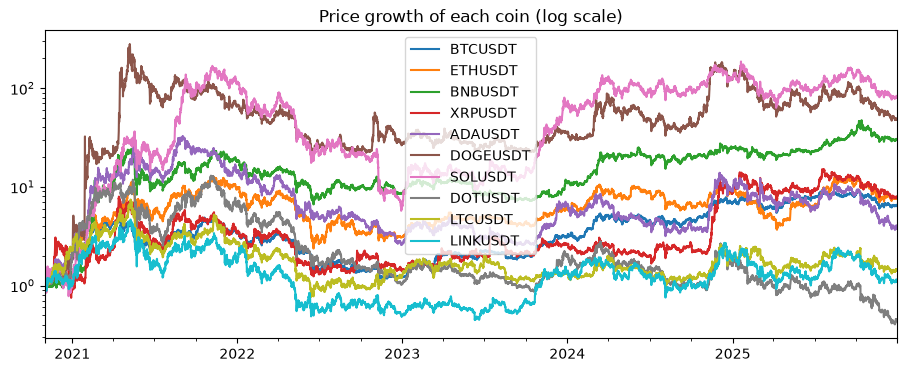

In [4]:
# Quick look at the data: number of 4h bars and the first / last date
print('Bars:', len(ret), '| From', ret.index[0], 'to', ret.index[-1])

# Growth of $1 in each coin: divide every price by the coin's first price, so all coins start at 1.
# (bfill fills any empty first values with the next real price, so the starting value is never NaN.)
# logy=True puts the y-axis on a log scale. Coins grew by very different amounts (SOL ~80x, DOT fell
# by more than half), and on a normal axis SOL would squash every other line flat near the bottom.
# On a log scale, equal % moves look equally big (1 -> 2 is the same height as 10 -> 20).
# figsize=(11,4) sets the chart size in inches: 11 wide, 4 tall.
(px / px.bfill().iloc[0]).plot(logy=True, figsize=(11,4), title='Price growth of each coin (log scale)')
plt.show()

## 2. Helper functions

* `N = 6*365`: crypto trades every day, so a year has 6 × 365 four-hour bars. Used to annualize.
* `xs_portfolio(signal)`: ranks the coins by a signal, subtracts the average rank and scales so the absolute weights add up to 1. High signal = long, low signal = short, and the portfolio is dollar-neutral.
* `backtest(port)`: gross return, turnover, and net return after costs. The portfolio is shifted by one bar so it only earns the *next* bar's return (no look-ahead).
* `compute_stats(rets)`: annual return, volatility, Sharpe, max drawdown, and beta / alpha / correlation against Bitcoin.

In [5]:
N = 6 * 365            # 4h bars per year
# Trading cost, as a fraction of every dollar traded. 1 bp (basis point) = 0.01% = 0.0001.
# I assume 20 bps for market orders:
#   7 bps commission (the exchange's fee) + 13 bps slippage (buying a bit above / selling a bit
#   below the quoted price, from crossing the bid-ask spread and moving the price).
# Example: trading $10,000 of coins costs $10,000 * 0.0020 = $20.
# backtest() uses this: net return = gross return - turnover * COST
COST = 0.0020
# Split the history into two date ranges. slice(start, end) is just a saved "from date - to date" range.
# Writing ret.loc[train] is the same as ret.loc['2021-01-01':'2023-12-31'] (both end dates included).
#   train: 2021-2023, used to test ideas and make every choice (look-backs, half-lives, weights)
#   test:  2024-2025, only used at the very end to check the strategy on data it has never seen
train = slice('2021-01-01', '2023-12-31')
test = slice('2024-01-01', '2025-12-31')

# Bitcoin's returns, used as the "market" benchmark for beta / alpha and for residual returns
btc = ret['BTCUSDT']

# Turn a signal into portfolio weights. Example for one bar, 4 coins:
#   signal:            A = +5%   B = -2%   C = +1%   D = +3%
#   1) rank:           A = 4     B = 1     C = 2     D = 3      (1 = lowest signal)
#   2) minus avg 2.5:  A = 1.5   B = -1.5  C = -0.5  D = 0.5    (positive = long, negative = short)
#   3) / sum|x| = 4:   A = 0.375 B = -0.375 C = -0.125 D = 0.125
# Result: 50% long, 50% short (dollar-neutral), and the strongest signals get the biggest weights.
def xs_portfolio(signal):
    port = signal.rank(axis=1)                              # 1) rank coins against each other in each row (bar)
    port = port.subtract(port.mean(axis=1), axis=0)         # 2) subtract the row's average rank -> longs and shorts cancel
    port = port.divide(port.abs().sum(axis=1), axis=0)      # 3) scale so total |weights| = 1 (100% of capital)
    return port.fillna(0)                                   # coins with no signal (missing data) get weight 0

def backtest(port, cost=COST):
    gross = (port.shift() * ret).sum(axis=1)
    turnover = port.diff().abs().sum(axis=1).shift()      # how much of the portfolio was traded
    net = gross - turnover * cost
    return pd.DataFrame({'gross': gross, 'net': net, 'turnover': turnover})

# lambda = a short, one-line function. This line is the same as:
#     def get_sharpe(x):
#         return x.mean() / x.std() * np.sqrt(N)
# Sharpe ratio = average return / volatility, annualized with sqrt(N) (N = 4h bars per year).
get_sharpe = lambda x: x.mean() / x.std() * np.sqrt(N)

def compute_stats(rets):
    stats = {}
    stats['avg'] = rets.mean() * N
    stats['vol'] = rets.std() * np.sqrt(N)
    stats['sharpe'] = stats['avg'] / stats['vol']
    cum = rets.cumsum()
    stats['max_dd'] = (cum - cum.cummax()).min()
    stats['beta'] = rets.apply(lambda x: x.cov(btc) / btc.loc[x.index].var())
    stats['alpha'] = stats['avg'] - stats['beta'] * btc.loc[rets.index].mean() * N
    stats['corr_btc'] = rets.corrwith(btc)
    return pd.DataFrame(stats)

## 3. Time horizon: where is reversal and where is momentum?

By time horizon I mean how far back I look to decide which coins are the "winners" and which are the "losers". With a 4-hour horizon, the winners are the coins that went up the most in the last 4 hours. With a 7-day horizon, they're the coins that went up the most over the past week.

Then the question is what those winners do next. If they keep outperforming, that's momentum. If they fall back, that's reversal. My expectation going in was reversal at short horizons (overreactions that bounce back) and momentum at longer ones (trends that continue).

For each horizon I go long the past winners and short the past losers and look at the Sharpe:
* positive Sharpe = momentum
* negative Sharpe = reversal (so the trade that makes money is the opposite one: buy losers, short winners)

I test horizons from 4 hours to 30 days. I also run a "skip" version that ignores the most recent bar (`shift(2)` instead of `shift()`). If the most recent bar is where the reversal is, skipping it should make momentum cleaner.

In [6]:
horizons = [1, 2, 3, 6, 12, 18, 42, 84, 180]   # in 4h bars: 4h, 8h, 12h, 1d, 2d, 3d, 7d, 14d, 30d

sr, sr_skip = {}, {}
for hor in horizons:
    port = xs_portfolio(ret.rolling(hor).mean())
    sr[hor] = get_sharpe(backtest(port)['gross'].loc[train])
    sr_skip[hor] = get_sharpe(backtest(port.shift())['gross'].loc[train])   # skip the most recent bar

horizon = pd.DataFrame({'sharpe': sr, 'sharpe_skip': sr_skip})
horizon.index = [f'{h*4}h' for h in horizons]
horizon

,sharpe,sharpe_skip
4h,-0.297635,1.078544
8h,0.641832,1.769133
12h,1.491947,2.649031
24h,1.679096,2.108239
48h,1.908127,1.965888
72h,1.966443,2.135573
168h,1.863756,1.854901
336h,1.156813,1.321799
720h,1.563851,1.681048


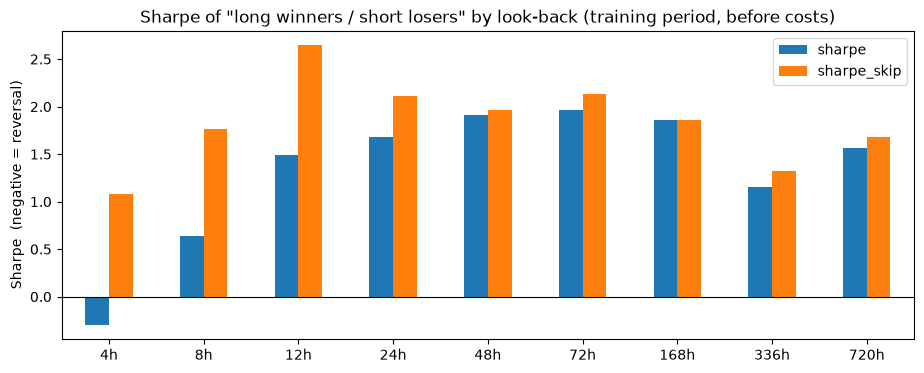

In [7]:
horizon.plot(kind='bar', figsize=(11,4), rot=0,
             title='Sharpe of "long winners / short losers" by look-back (training period, before costs)')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Sharpe  (negative = reversal)')
plt.show()

How I pick the two base strategies (training period only):
* Reversal: the short horizon (1 day or less) with the most negative Sharpe. The signal gets a minus sign so the strategy buys recent losers.
* Momentum: the longer horizon (1 day or more) with the highest Sharpe in the skip version.

In [8]:
short_h = [h for h in horizons if h <= 6]
long_h = [h for h in horizons if h >= 6]
rev_hor = min(short_h, key=lambda h: sr[h])
mom_hor = max(long_h, key=lambda h: sr_skip[h])
print(f'Reversal look-back: {rev_hor*4}h   Momentum look-back: {mom_hor*4}h')

rev_signal = -ret.rolling(rev_hor).mean()             # minus sign: buy losers, sell winners
mom_signal = ret.rolling(mom_hor).mean().shift()      # skip the most recent bar

port_rev = xs_portfolio(rev_signal)
port_mom = xs_portfolio(mom_signal)

Reversal look-back: 4h   Momentum look-back: 72h


**Multi-horizon momentum.** Momentum shows up at pretty much every horizon from 12 hours to 30 days, so instead of betting on one window I also tried averaging each coin's momentum rank over 3, 7, 14 and 30 days. The signal is steadier and changes more slowly, which should help a lot once costs come in (Section 8).

In [9]:
multi_signal = sum(ret.rolling(h).mean().shift().rank(axis=1) for h in [18, 42, 84, 180])   # 3d, 7d, 14d, 30d
port_mom_multi = xs_portfolio(multi_signal)
print('Multi-horizon momentum Sharpe (train, gross):', round(get_sharpe(backtest(port_mom_multi)['gross'].loc[train]), 2))

Multi-horizon momentum Sharpe (train, gross): 1.98


## 4. Volume: is reversal stronger on quiet moves?

The idea: price moves driven by uninformed trading (no news, not much activity) should reverse, while moves on heavy volume are more likely to carry real information and stick.

To test it I compare each coin's recent volume with its normal volume (30-day average). Each bar I split the coins into a low-volume half and a high-volume half and run the reversal strategy on each half separately.

In [10]:
rel_vol = vol.rolling(rev_hor).mean() / vol.rolling(180).mean()   # recent volume vs. normal volume
low_vol = rel_vol.rank(axis=1, pct=True) <= 0.5                        # True for the quieter half of coins

port_rev_lowvol = xs_portfolio(rev_signal.where(low_vol))
port_rev_highvol = xs_portfolio(rev_signal.where(~low_vol))

volume_test = pd.Series({
    'Reversal - all coins': get_sharpe(backtest(port_rev)['gross'].loc[train]),
    'Reversal - low volume': get_sharpe(backtest(port_rev_lowvol)['gross'].loc[train]),
    'Reversal - high volume': get_sharpe(backtest(port_rev_highvol)['gross'].loc[train]),
})
volume_test.to_frame('sharpe (train, gross)')

,"sharpe (train, gross)"
Reversal - all coins,0.297635
Reversal - low volume,2.013190
Reversal - high volume,-0.683188


## 5. Residual returns

Most coins move with Bitcoin. If I strip that common move out, what's left (the residual) might mean-revert more cleanly. I use a rolling 30-day beta to BTC:

`beta = correlation × (coin vol / BTC vol)` and `residual = ret − beta × BTC ret`

and rebuild the reversal and momentum signals on the residuals.

In [11]:
corr = ret.rolling(180).corr(btc)
vols = ret.rolling(180).std()
beta = (corr * vols).divide(vols['BTCUSDT'], axis=0).shift()   # shift: only use beta known before the bar
resid = ret - beta.multiply(btc, axis=0)

port_rev_resid = xs_portfolio(-resid.rolling(rev_hor).mean())
port_mom_resid = xs_portfolio(resid.rolling(mom_hor).mean().shift())

resid_test = pd.Series({
    'Reversal - raw': get_sharpe(backtest(port_rev)['gross'].loc[train]),
    'Reversal - residual': get_sharpe(backtest(port_rev_resid)['gross'].loc[train]),
    'Momentum - raw': get_sharpe(backtest(port_mom)['gross'].loc[train]),
    'Momentum - residual': get_sharpe(backtest(port_mom_resid)['gross'].loc[train]),
})
resid_test.to_frame('sharpe (train, gross)')

,"sharpe (train, gross)"
Reversal - raw,0.297635
Reversal - residual,0.095145
Momentum - raw,2.135573
Momentum - residual,1.912496


## 6. Seasonality

**6a. When do the strategies make money?** Weekday vs. weekend (institutions mostly trade on weekdays) and time of day in UTC. For reference, the US stock market opens at 13:30-14:30 UTC.

In [12]:
rev_gross = backtest(port_rev)['gross'].loc[train]
mom_gross = backtest(port_mom)['gross'].loc[train]

weekend = np.where(rev_gross.index.dayofweek >= 5, 'weekend', 'weekday')
pd.DataFrame({'reversal': rev_gross.groupby(weekend).apply(get_sharpe),
              'momentum': mom_gross.groupby(weekend).apply(get_sharpe)})

,reversal,momentum
weekday,0.399805,1.988467
weekend,-0.007870,2.586517


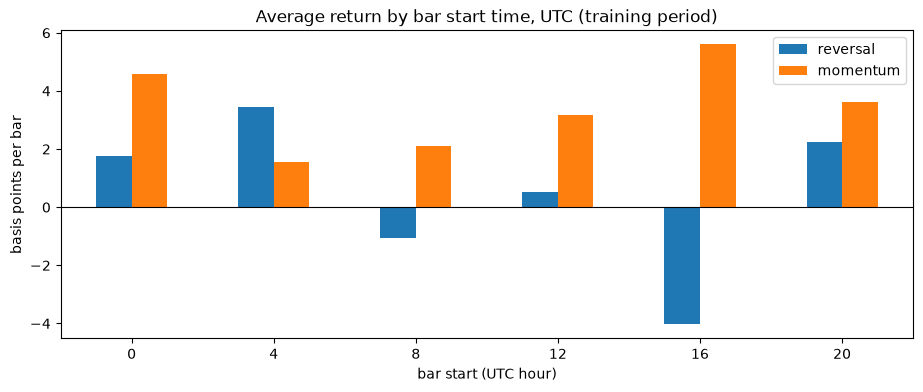

In [13]:
by_hour = pd.DataFrame({'reversal': rev_gross.groupby(rev_gross.index.hour).mean(),
                        'momentum': mom_gross.groupby(mom_gross.index.hour).mean()}) * 10000
by_hour.plot(kind='bar', rot=0, figsize=(11,4), title='Average return by bar start time, UTC (training period)')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('basis points per bar')
plt.xlabel('bar start (UTC hour)')
plt.show()

**6b. Same-time-of-day momentum.** Do coins that tend to do well at a certain time of day keep doing well at that time?

Signal: each coin's average return in the same 4h slot of the day over the past 30 days. There are 6 bars a day, and I'm predicting the next bar, so the same slot yesterday is `shift(5)`, the day before is `shift(11)`, and so on.

In [14]:
seasonal_signal = sum(ret.shift(5 + 6*k) for k in range(30)) / 30
port_season = xs_portfolio(seasonal_signal)
print('Seasonality Sharpe (train, gross):', round(get_sharpe(backtest(port_season)['gross'].loc[train]), 2))

Seasonality Sharpe (train, gross): 3.39


## 7. Market regimes: more reversal when things are stressed?

My hypothesis was that reversal should be stronger when markets are dislocated, since that's when liquidity providers get paid the most. I measure dislocation with return dispersion (how differently the coins moved over the last day) and split the training period into low, medium and high thirds.

In [15]:
dispersion = ret.std(axis=1).rolling(6).mean().shift()     # previous day's dispersion (known in advance)
regime = pd.qcut(dispersion.loc[train], 3, labels=['low', 'medium', 'high'])
rev_gross.groupby(regime).apply(get_sharpe).to_frame('reversal sharpe by dispersion regime')

,reversal sharpe by dispersion regime
low,1.428709
medium,1.020585
high,-0.204766


## 8. Trading costs

Every change to the portfolio costs 20 bps on the amount traded. Short-term strategies trade a lot, so this is where most of them die.

To trade less I smooth the portfolio with `port.ewm(halflife).mean()`, which only moves part of the way toward the new target each bar. Longer half-life = less trading, but a slower signal. I tried a range of half-lives on every strategy.

In [16]:
candidates = {
    'Reversal': port_rev,
    'Reversal - low volume': port_rev_lowvol,
    'Reversal - residual': port_rev_resid,
    'Momentum': port_mom,
    'Momentum - residual': port_mom_resid,
    'Momentum - multi-horizon': port_mom_multi,
    'Seasonality': port_season,
}
halflives = [0, 1, 3, 6, 12, 24, 48]   # in 4h bars: 24 = 4 days, 48 = 8 days

net_sr, turnover = {}, {}
for name, port in candidates.items():
    net_sr[name], turnover[name] = {}, {}
    for hl in halflives:
        smooth = port if hl == 0 else port.ewm(halflife=hl).mean()
        res = backtest(smooth).loc[train]
        net_sr[name][hl] = get_sharpe(res['net'])
        turnover[name][hl] = res['turnover'].mean()

net_sr = pd.DataFrame(net_sr).T
net_sr.columns.name = 'half-life (bars)'
print('Net Sharpe after 20 bps costs (training period):')
net_sr

Net Sharpe after 20 bps costs (training period):


half-life (bars),0,1,3,6,12,24,48
Reversal,-16.198234,-10.369504,-6.979425,-5.740241,-4.814571,-3.961162,-3.047943
Reversal - low volume,-20.196899,-15.680282,-10.652034,-7.945111,-5.766790,-4.040164,-2.758555
Reversal - residual,-16.490731,-10.643848,-7.112995,-5.797488,-4.859371,-4.037661,-3.118737
Momentum,-2.010158,-0.759498,-0.387594,-0.402959,-0.408758,-0.337475,-0.201983
Momentum - residual,-2.220767,-0.812036,-0.306216,-0.278653,-0.225407,-0.082649,0.067852
Momentum - multi-horizon,-1.211394,-0.032374,0.361632,0.398138,0.391782,0.423984,0.444580
Seasonality,-15.066005,-9.914497,-4.625986,-2.295572,-0.968885,-0.209185,0.167908


In [17]:
print('Average turnover per bar (fraction of the portfolio traded):')
pd.DataFrame(turnover).T

Average turnover per bar (fraction of the portfolio traded):


,0,1,3,6,12,24,48
Reversal,1.335012,0.559032,0.214476,0.111059,0.056505,0.028507,0.014326
Reversal - low volume,1.557357,0.664709,0.247498,0.124984,0.062104,0.030733,0.015228
Reversal - residual,1.333613,0.558086,0.214390,0.111025,0.056498,0.028505,0.014324
Momentum,0.333443,0.192153,0.108400,0.072099,0.044224,0.025001,0.013359
Momentum - residual,0.332225,0.191924,0.108285,0.072163,0.044272,0.025023,0.013369
Momentum - multi-horizon,0.249006,0.134117,0.071540,0.047219,0.030114,0.018394,0.010781
Seasonality,1.289376,0.546825,0.203769,0.103682,0.052401,0.026534,0.013508


Final picks: the best reversal-type strategy and the best momentum-type strategy (plain, residual, multi-horizon or seasonality), ranked by net Sharpe in the training period.

In [18]:
rev_names = ['Reversal', 'Reversal - low volume', 'Reversal - residual']
mom_names = ['Momentum', 'Momentum - residual', 'Momentum - multi-horizon', 'Seasonality']

final = {}
for label, names in [('reversal', rev_names), ('momentum', mom_names)]:
    best_name = net_sr.loc[names].max(axis=1).idxmax()
    best_hl = net_sr.loc[best_name].idxmax()
    port = candidates[best_name]
    final[label] = port if best_hl == 0 else port.ewm(halflife=best_hl).mean()
    print(f'{label}: {best_name}, half-life {best_hl} -> net Sharpe {net_sr.loc[best_name, best_hl]:.2f}')

strat = pd.DataFrame({label: backtest(port)['net'] for label, port in final.items()}).loc['2021-01-01':]

reversal: Reversal - low volume, half-life 48 -> net Sharpe -2.76
momentum: Momentum - multi-horizon, half-life 48 -> net Sharpe 0.44


In [19]:
# How much do costs take away? Sharpe of the final strategies before and after costs (training period)
pd.DataFrame({label: {'before costs': get_sharpe(backtest(port)['gross'].loc[train]),
                      'after 20 bps': get_sharpe(backtest(port)['net'].loc[train]),
                      'after 7 bps (limit orders)': get_sharpe(backtest(port, cost=0.0007)['net'].loc[train])}
              for label, port in final.items()}).round(2)

,reversal,momentum
before costs,-0.61,0.72
after 20 bps,-2.76,0.44
after 7 bps (limit orders),-1.36,0.62


## 9. Combining the strategies

Reversal and momentum are opposite bets, so in principle they should diversify each other. I combine them with mean-variance weights (`inverse(covariance) @ mean`) estimated on the training period only.

If a strategy lost money after costs, the optimizer would want to short it, which doesn't make sense, so negative weights are set to zero. If one strategy ends up with zero weight, the combination is just the other one.

In [20]:
print('Correlation between the strategies (train):')
print(strat.loc[train].corr().round(2))

def optimal_weights(sigma, mu):
    wgt = np.linalg.inv(sigma) @ mu
    wgt = wgt / np.abs(wgt).sum()
    return wgt

cols = ['reversal', 'momentum']
wgt = optimal_weights(strat.loc[train, cols].cov(), strat.loc[train, cols].mean())
wgt = pd.Series(wgt, cols).clip(lower=0)
if wgt.sum() == 0:                 # both lost money after costs -> just split 50/50
    wgt = pd.Series(0.5, cols)
wgt = wgt / wgt.sum()
print('\nWeights:'); print(wgt.round(2))

strat['combo'] = (strat[wgt.index] * wgt).sum(axis=1)

# Scale the combo to 20% yearly volatility (a typical target for a hedge-fund strategy),
# using the training-period volatility so the test period isn't used.
lev = 0.20 / (strat['combo'].loc[train].std() * np.sqrt(N))
strat['combo_20vol'] = strat['combo'] * lev
print(f'\nLeverage for 20% vol: {lev:.2f}x')

Correlation between the strategies (train):
          reversal  momentum
reversal      1.00     -0.11
momentum     -0.11      1.00

Weights:
reversal    0.0
momentum    1.0
dtype: float64

Leverage for 20% vol: 1.16x


## 10. Performance

Everything is after 20 bps costs, except one extra line showing the momentum strategy traded with limit orders (7 bps). Bitcoin buy-and-hold is there for comparison.
* avg / vol / sharpe: annualized return, volatility and Sharpe ratio
* max_dd: largest peak-to-trough drop in cumulative returns
* beta / alpha: exposure to Bitcoin and the return left over after removing it (beta near 0 = market-neutral)

In [21]:
strat['momentum (7 bps limit orders)'] = backtest(final['momentum'], cost=0.0007)['net']
strat['BTC buy & hold'] = btc

print('TRAINING period 2021-2023 (used to build the strategy)')
display(compute_stats(strat.loc[train]).round(3))

print('TEST period 2024-2025 (never seen before, the honest result)')
display(compute_stats(strat.loc[test]).round(3))

TRAINING period 2021-2023 (used to build the strategy)


,avg,vol,sharpe,max_dd,beta,alpha,corr_btc
reversal,-0.086,0.031,-2.759,-0.265,0.003,-0.087,0.073
momentum,0.076,0.172,0.445,-0.288,0.002,0.076,0.009
combo,0.076,0.172,0.445,-0.288,0.002,0.076,0.009
combo_20vol,0.089,0.200,0.445,-0.335,0.003,0.088,0.009
momentum (7 bps limit orders),0.107,0.172,0.623,-0.232,0.002,0.106,0.009
BTC buy & hold,0.346,0.662,0.522,-1.255,1.000,0.000,1.000


TEST period 2024-2025 (never seen before, the honest result)


,avg,vol,sharpe,max_dd,beta,alpha,corr_btc
reversal,-0.065,0.022,-2.960,-0.133,0.009,-0.070,0.196
momentum,0.068,0.131,0.515,-0.139,-0.015,0.075,-0.056
combo,0.068,0.131,0.515,-0.139,-0.015,0.075,-0.056
combo_20vol,0.079,0.153,0.515,-0.162,-0.018,0.087,-0.056
momentum (7 bps limit orders),0.098,0.131,0.745,-0.123,-0.015,0.105,-0.056
BTC buy & hold,0.485,0.482,1.007,-0.406,1.000,-0.000,1.000


In [22]:
print('Sharpe ratio in each year:')
strat.groupby(strat.index.year).apply(lambda x: x.apply(get_sharpe)).round(2)

Sharpe ratio in each year:


,reversal,momentum,combo,combo_20vol,momentum (7 bps limit orders),BTC buy & hold
2021,-2.67,0.82,0.82,0.82,0.94,0.97
2022,-3.42,-0.30,-0.30,-0.30,-0.05,-1.37
2023,-2.88,0.57,0.57,0.57,0.81,2.44
2024,-2.36,0.54,0.54,0.54,0.74,1.79
2025,-3.78,0.50,0.50,0.50,0.77,0.09


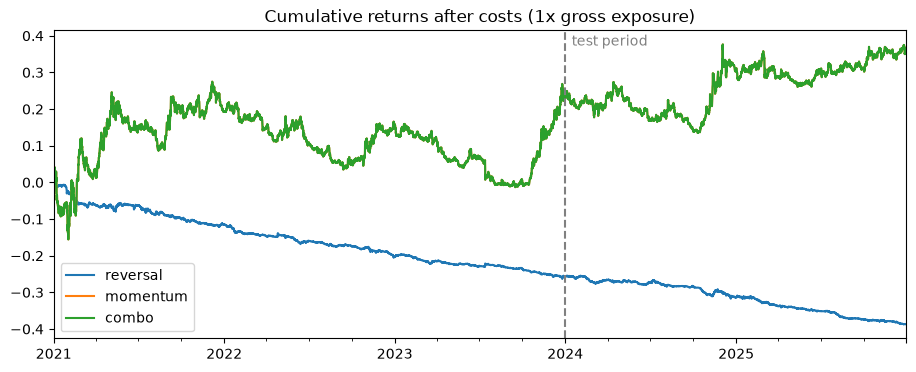

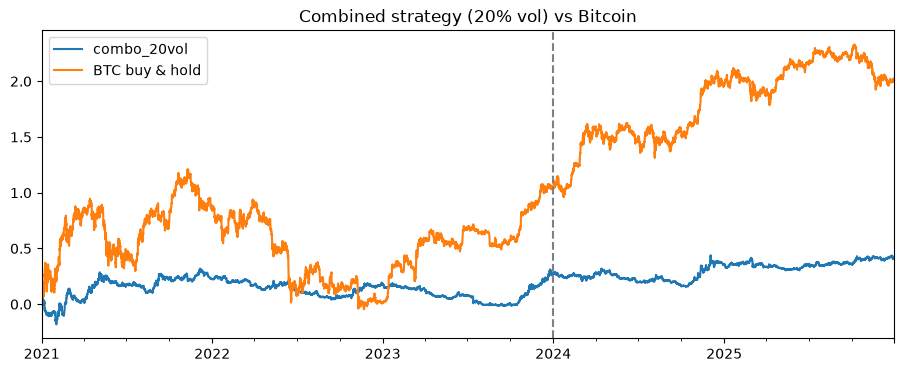

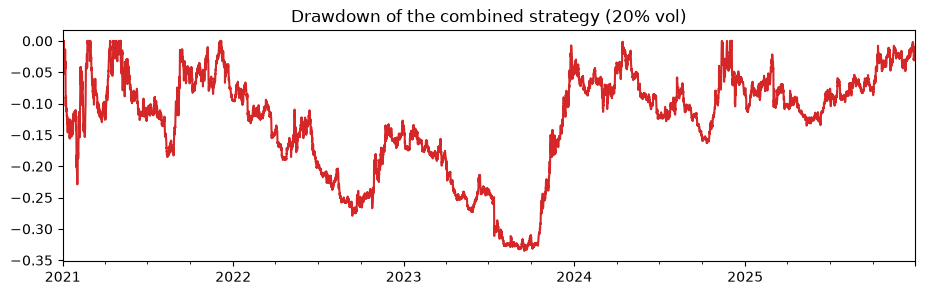

In [23]:
ax = strat[['reversal', 'momentum', 'combo']].cumsum().plot(figsize=(11,4),
        title='Cumulative returns after costs (1x gross exposure)')
ax.axvline(pd.Timestamp('2024-01-01'), color='gray', linestyle='--')
ax.text(pd.Timestamp('2024-01-15'), ax.get_ylim()[1]*0.9, 'test period', color='gray')
plt.show()

ax = strat[['combo_20vol', 'BTC buy & hold']].cumsum().plot(figsize=(11,4),
        title='Combined strategy (20% vol) vs Bitcoin')
ax.axvline(pd.Timestamp('2024-01-01'), color='gray', linestyle='--')
plt.show()

cum = strat['combo_20vol'].cumsum()
(cum - cum.cummax()).plot(figsize=(11,3), color='tab:red', title='Drawdown of the combined strategy (20% vol)')
plt.show()

## 11. Findings

(Numbers below are from my run on Binance data from Nov 2020 to Dec 2025. The next cell prints them from the live results.)

**Time horizon.** Only the 4h look-back showed reversal, and it was weak (Sharpe -0.30 for long winners). From 8 hours all the way to 30 days it was momentum, strongest between 12 hours and 7 days (Sharpe roughly 1.5 to 2.1 before costs). Skipping the most recent bar made momentum stronger at most horizons, e.g. 12h went from 1.49 to 2.65, so the latest bar is where the reversal sits.

**Volume.** Reversal is concentrated in quiet coins: Sharpe 2.01 on the low-volume half vs -0.68 on the high-volume half. That's consistent with the uninformed-trading idea.

**Residual returns.** Taking out Bitcoin didn't help (reversal 0.30 to 0.10, momentum 2.14 to 1.91). I think this is because the portfolios are already dollar-neutral across 10 coins that all move with BTC, so most of the market move cancels out anyway.

**Seasonality.** Same-time-of-day momentum was the strongest signal I found before costs (Sharpe 3.39). Momentum also worked better on weekends (2.59) than weekdays (1.99), while reversal only showed up on weekdays.

**Market regimes.** This went the opposite way from what I expected. Reversal was strongest when dispersion was low (1.43) and disappeared when it was high (-0.20).

**Costs.** This was the deciding factor. The 4h reversal strategy turns over about 134% of the portfolio every bar, so at 20 bps it ends up with a Sharpe around -16. Even with 8-day smoothing, none of the reversal or seasonality versions made money after costs. Multi-horizon momentum with an 8-day half-life only trades about 1% per bar and kept a net Sharpe of 0.44 in training.

**Combination.** Before costs, low-volume reversal and multi-horizon momentum are basically uncorrelated (0.01) and a 50/50 mix has a Sharpe around 2.8. After costs reversal loses money, the optimizer gives it zero weight, and the final portfolio is just the momentum strategy.

**Out of sample (2024-2025).** The final strategy held up on data it had never seen:

| Test 2024-2025 | 20 bps costs | 7 bps (limit orders) | Bitcoin |
|---|---|---|---|
| Annual return | 6.8% | 9.8% | 48.5% |
| Volatility | 13.1% | 13.1% | 48.2% |
| Sharpe | 0.51 | 0.75 | 1.01 |
| Max drawdown | -13.9% | -12.3% | -40.6% |
| Beta to BTC | -0.02 | -0.02 | 1.00 |

It's market-neutral (beta about 0, correlation with BTC -0.06), so it's something you'd hold alongside crypto rather than instead of it. The Sharpe was positive in 4 of the 5 years; 2022 was the only losing year.

Overall: there are strong short-term patterns in crypto (low-volume reversal, intraday seasonality, short-horizon momentum), but at 20 bps a trade only the slow signals survive. Trading less mattered more than finding a stronger signal.

In [24]:
t = compute_stats(strat.loc[test])
print(f"1. Reversal appears at look-backs of {[i for i in horizon.index if horizon.loc[i,'sharpe'] < 0]}, "
      f"momentum at {[i for i in horizon.index if horizon.loc[i,'sharpe'] > 0]}.")
print(f"2. Reversal Sharpe on low-volume coins {volume_test.iloc[1]:.2f} vs high-volume coins {volume_test.iloc[2]:.2f}.")
print(f"3. Reversal Sharpe on raw returns {resid_test.iloc[0]:.2f} vs residual returns {resid_test.iloc[1]:.2f}.")
print(f"4. After 20 bps costs, the best training net Sharpes are: reversal "
      f"{net_sr.loc[rev_names].max().max():.2f}, momentum {net_sr.loc[mom_names].max().max():.2f}.")
print(f"5. Test period (2024-2025), final strategy after 20 bps: return {t.loc['combo','avg']:.1%}, "
      f"Sharpe {t.loc['combo','sharpe']:.2f}, max drawdown {t.loc['combo','max_dd']:.1%}, "
      f"beta to BTC {t.loc['combo','beta']:.2f}.")

1. Reversal appears at look-backs of ['4h'], momentum at ['8h', '12h', '24h', '48h', '72h', '168h', '336h', '720h'].
2. Reversal Sharpe on low-volume coins 2.01 vs high-volume coins -0.68.
3. Reversal Sharpe on raw returns 0.30 vs residual returns 0.10.
4. After 20 bps costs, the best training net Sharpes are: reversal -2.76, momentum 0.44.
5. Test period (2024-2025), final strategy after 20 bps: return 6.8%, Sharpe 0.51, max drawdown -13.9%, beta to BTC -0.02.


### Limitations
* Survivorship bias: these are coins that are big today. A cleaner test would pick the universe as it looked at each point in time.
* 20 bps is a flat estimate. Real slippage depends on size.
* I assume every coin can be shorted for free. In practice that would be done with perpetual futures, which charge funding.
* Trades are assumed to fill at the close of each 4h bar.

### Next steps
* Seasonality and low-volume reversal are strong before costs. Worth trying to trade them only when the expected edge is bigger than the cost.
* A bigger universe (30+ coins) for a smoother ranking.
* Execute the momentum leg with limit orders. It's slow enough that this seems realistic, and it lifts the test Sharpe from 0.51 to 0.75.
* Add other "new information" data like social media activity or liquidations.